# Práctica 3 - K-Nearest Neighbors (KNN)
## Predicción de Cáncer de Mama - Breast Cancer Wisconsin Dataset
### Versión Didáctica con enfoque educativo paso a paso

---

##  Objetivo de la Práctica

Entrenar un modelo **KNN** para predecir si un tumor es **benigno** o **maligno**
usando el dataset de cáncer de mama de Wisconsin.

### Diferencia con Naive Bayes (Práctica 2):
- **Naive Bayes**: Calcula probabilidades, asume independencia entre características
- **KNN**: Clasifica según proximidad a vecinos más cercanos (sin asumir distribución)

---


In [212]:
# ==============================================================================
#  BLOQUE 1: IMPORTACIÓN DE LIBRERÍAS
# ==============================================================================

"""
En este bloque importamos todas las librerías necesarias para:
- Manipulación de datos (pandas, numpy)
- Visualización (matplotlib, seaborn)
- Machine Learning (sklearn)
"""
#!pip install kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
import kagglehub

# Librerías de preprocesamiento
from sklearn.preprocessing import StandardScaler

# Librerías de división de datos
from sklearn.model_selection import train_test_split, StratifiedKFold

# Modelo KNN
from sklearn.neighbors import KNeighborsClassifier

# Métricas de evaluación
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

# Para descargar archivos en Colab
from google.colab import files

# Configuración de estilo para gráficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [213]:
# ==============================================================================
#  BLOQUE 2: CARGA DEL DATASET
# ==============================================================================

"""
TAREA 1.1: Cargar el dataset en un DataFrame llamado 'datos'

El dataset contiene información sobre tumores de mama con características
como radio, textura, perímetro, área, etc.
"""

# Cargardatos desde url usando kagglehub
datos = pd.read_csv(kagglehub.dataset_download('uciml/breast-cancer-wisconsin-data', 'data.csv'))

print("="*70)
print(" DATASET CARGADO CORRECTAMENTE")
print("="*70)
print(f"Dimensiones: {datos.shape[0]} filas × {datos.shape[1]} columnas")
print(f"Memoria utilizada: {datos.memory_usage(deep=True).sum() / 1024:.2f} KB")

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
 DATASET CARGADO CORRECTAMENTE
Dimensiones: 569 filas × 33 columnas
Memoria utilizada: 170.16 KB


In [214]:
# ==============================================================================
#  BLOQUE 3: VISUALIZACIÓN INICIAL DEL DATASET
# ==============================================================================

"""
TAREA 1.2: Mostrar el dataset

Vamos a ver las primeras filas para entender la estructura de los datos
"""

print("\n" + "="*70)
print("TAREA 1.2: PRIMERAS FILAS DEL DATASET")
print("="*70)
print(datos.head(6))

print("\n Columnas del dataset:")
print(list(datos.columns))

# Información básica del dataset
print("\n Información general:")
print(datos.info())


TAREA 1.2: PRIMERAS FILAS DEL DATASET
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   
5    843786         M        12.45         15.70           82.57      477.1   

   smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030    

In [215]:
# ==============================================================================
#  BLOQUE 4: RESUMEN ESTADÍSTICO
# ==============================================================================

"""
TAREA 1.3: Mostrar resumen estadístico

Este resumen nos da información sobre:
- Media (mean)
- Desviación estándar (std)
- Valores mínimos y máximos
- Cuartiles (25%, 50%, 75%)
"""

print("\n" + "="*70)
print("TAREA 1.3: RESUMEN ESTADÍSTICO DEL DATASET")
print("="*70)
print(datos.describe())

# Verificar valores nulos
print("\n Verificación de valores nulos:")
print(datos.isnull().sum().sum())


TAREA 1.3: RESUMEN ESTADÍSTICO DEL DATASET
                 id  radius_mean  texture_mean  perimeter_mean    area_mean  \
count  5.690000e+02   569.000000    569.000000      569.000000   569.000000   
mean   3.037183e+07    14.127292     19.289649       91.969033   654.889104   
std    1.250206e+08     3.524049      4.301036       24.298981   351.914129   
min    8.670000e+03     6.981000      9.710000       43.790000   143.500000   
25%    8.692180e+05    11.700000     16.170000       75.170000   420.300000   
50%    9.060240e+05    13.370000     18.840000       86.240000   551.100000   
75%    8.813129e+06    15.780000     21.800000      104.100000   782.700000   
max    9.113205e+08    28.110000     39.280000      188.500000  2501.000000   

       smoothness_mean  compactness_mean  concavity_mean  concave points_mean  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048919   
s


TAREA 1.4: VISUALIZACIONES ESTADÍSTICAS


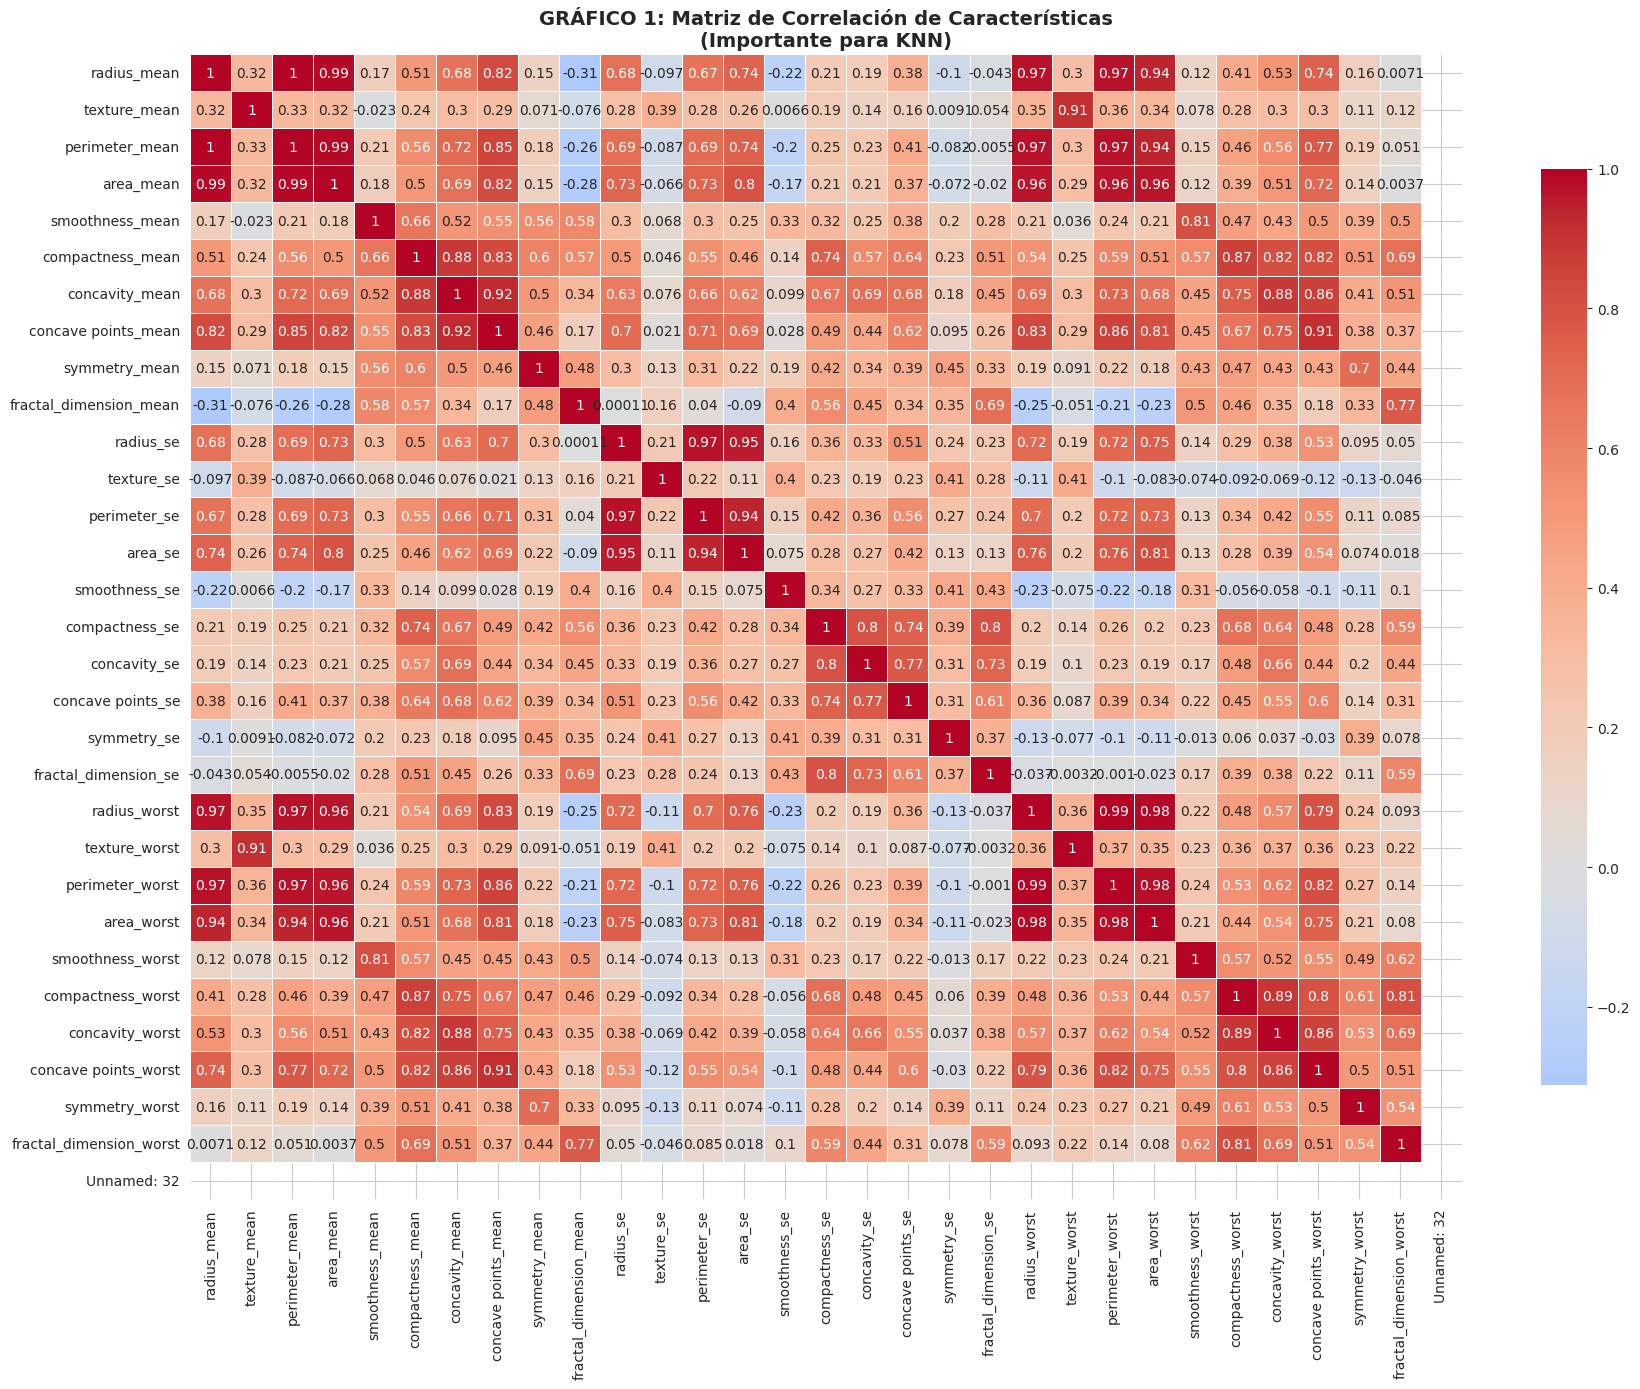

 Matriz de correlación generada
   Colores rojos oscuros = Correlación alta (características redundantes)
   Colores azules = Correlación baja o negativa


In [216]:
# ==============================================================================
#  BLOQUE 5: GRÁFICO 1 - MATRIZ DE CORRELACIÓN
# ==============================================================================

"""
TAREA 1.4: Visualizaciones estadísticas

GRÁFICO 1: Matriz de Correlación
Esta matriz nos ayuda a identificar características redundantes
(altamente correlacionadas entre sí)
"""

print("\n" + "="*70)
print("TAREA 1.4: VISUALIZACIONES ESTADÍSTICAS")
print("="*70)

# Eliminar columnas no numéricas para calcular correlación
columnas_numericas = datos.drop(['diagnosis', 'id'], axis=1, errors='ignore')

# Calcular matriz de correlación
correlacion = columnas_numericas.corr()

# Crear el gráfico
plt.figure(figsize=(18, 14))
sns.heatmap(correlacion,
            cmap='coolwarm',
            center=0,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8},
            xticklabels=True,
            yticklabels=True,
            annot=True)
plt.title('GRÁFICO 1: Matriz de Correlación de Características\n(Importante para KNN)',
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(" Matriz de correlación generada")
print("   Colores rojos oscuros = Correlación alta (características redundantes)")
print("   Colores azules = Correlación baja o negativa")

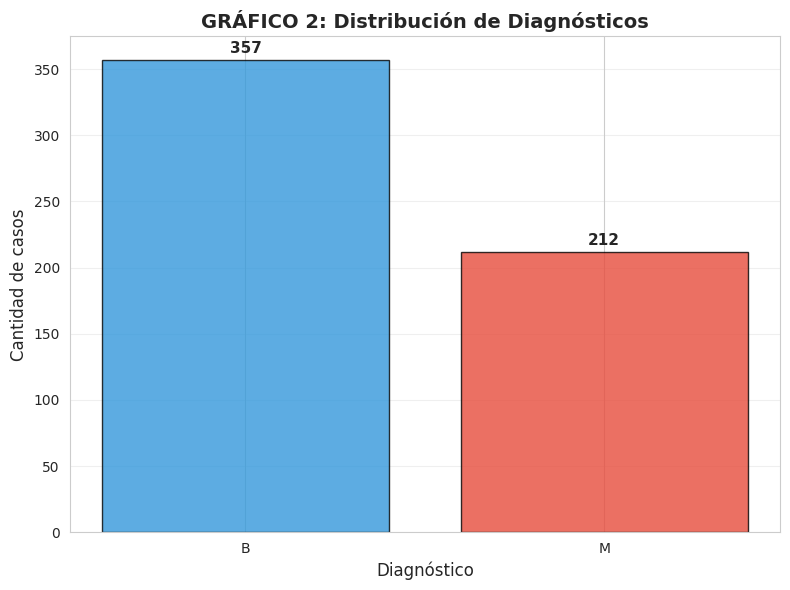

 Distribución:
   Benignos (B): 357 (62.7%)
   Malignos (M): 212 (37.3%)
   Balance:  Aceptable


In [217]:
# =======================================================
#  BLOQUE 6: GRÁFICO 2 - DISTRIBUCIÓN DE DIAGNÓSTICOS
# ==============================================================================

"""
GRÁFICO 2: Distribución de Diagnósticos

Este gráfico muestra cuántos casos benignos (B) y malignos (M) hay
en el dataset. Es importante verificar si hay balance entre clases.
"""

# Contar casos por diagnóstico
conteo = datos['diagnosis'].value_counts()

# Crear gráfico de barras
plt.figure(figsize=(8, 6))
colores = ['#3498db', '#e74c3c']  # Azul para B, Rojo para M
bars = plt.bar(conteo.index, conteo.values, color=colores,
               edgecolor='black', alpha=0.8)

plt.title('GRÁFICO 2: Distribución de Diagnósticos',
          fontsize=14, fontweight='bold')
plt.xlabel('Diagnóstico', fontsize=12)
plt.ylabel('Cantidad de casos', fontsize=12)

# Añadir valores sobre las barras
for i, (bar, v) in enumerate(zip(bars, conteo.values)):
    plt.text(bar.get_x() + bar.get_width()/2, v + 5, str(v),
             ha='center', fontweight='bold', fontsize=11)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Calcular porcentajes
total = conteo['B'] + conteo['M']
porcentaje_b = (conteo['B'] / total) * 100
porcentaje_m = (conteo['M'] / total) * 100

print(f" Distribución:")
print(f"   Benignos (B): {conteo['B']} ({porcentaje_b:.1f}%)")
print(f"   Malignos (M): {conteo['M']} ({porcentaje_m:.1f}%)")
print(f"   Balance: {' Aceptable' if 30 < porcentaje_m < 70 else '⚠️ Desbalanceado'}")


 Generando Pairplot (puede tardar unos segundos)...


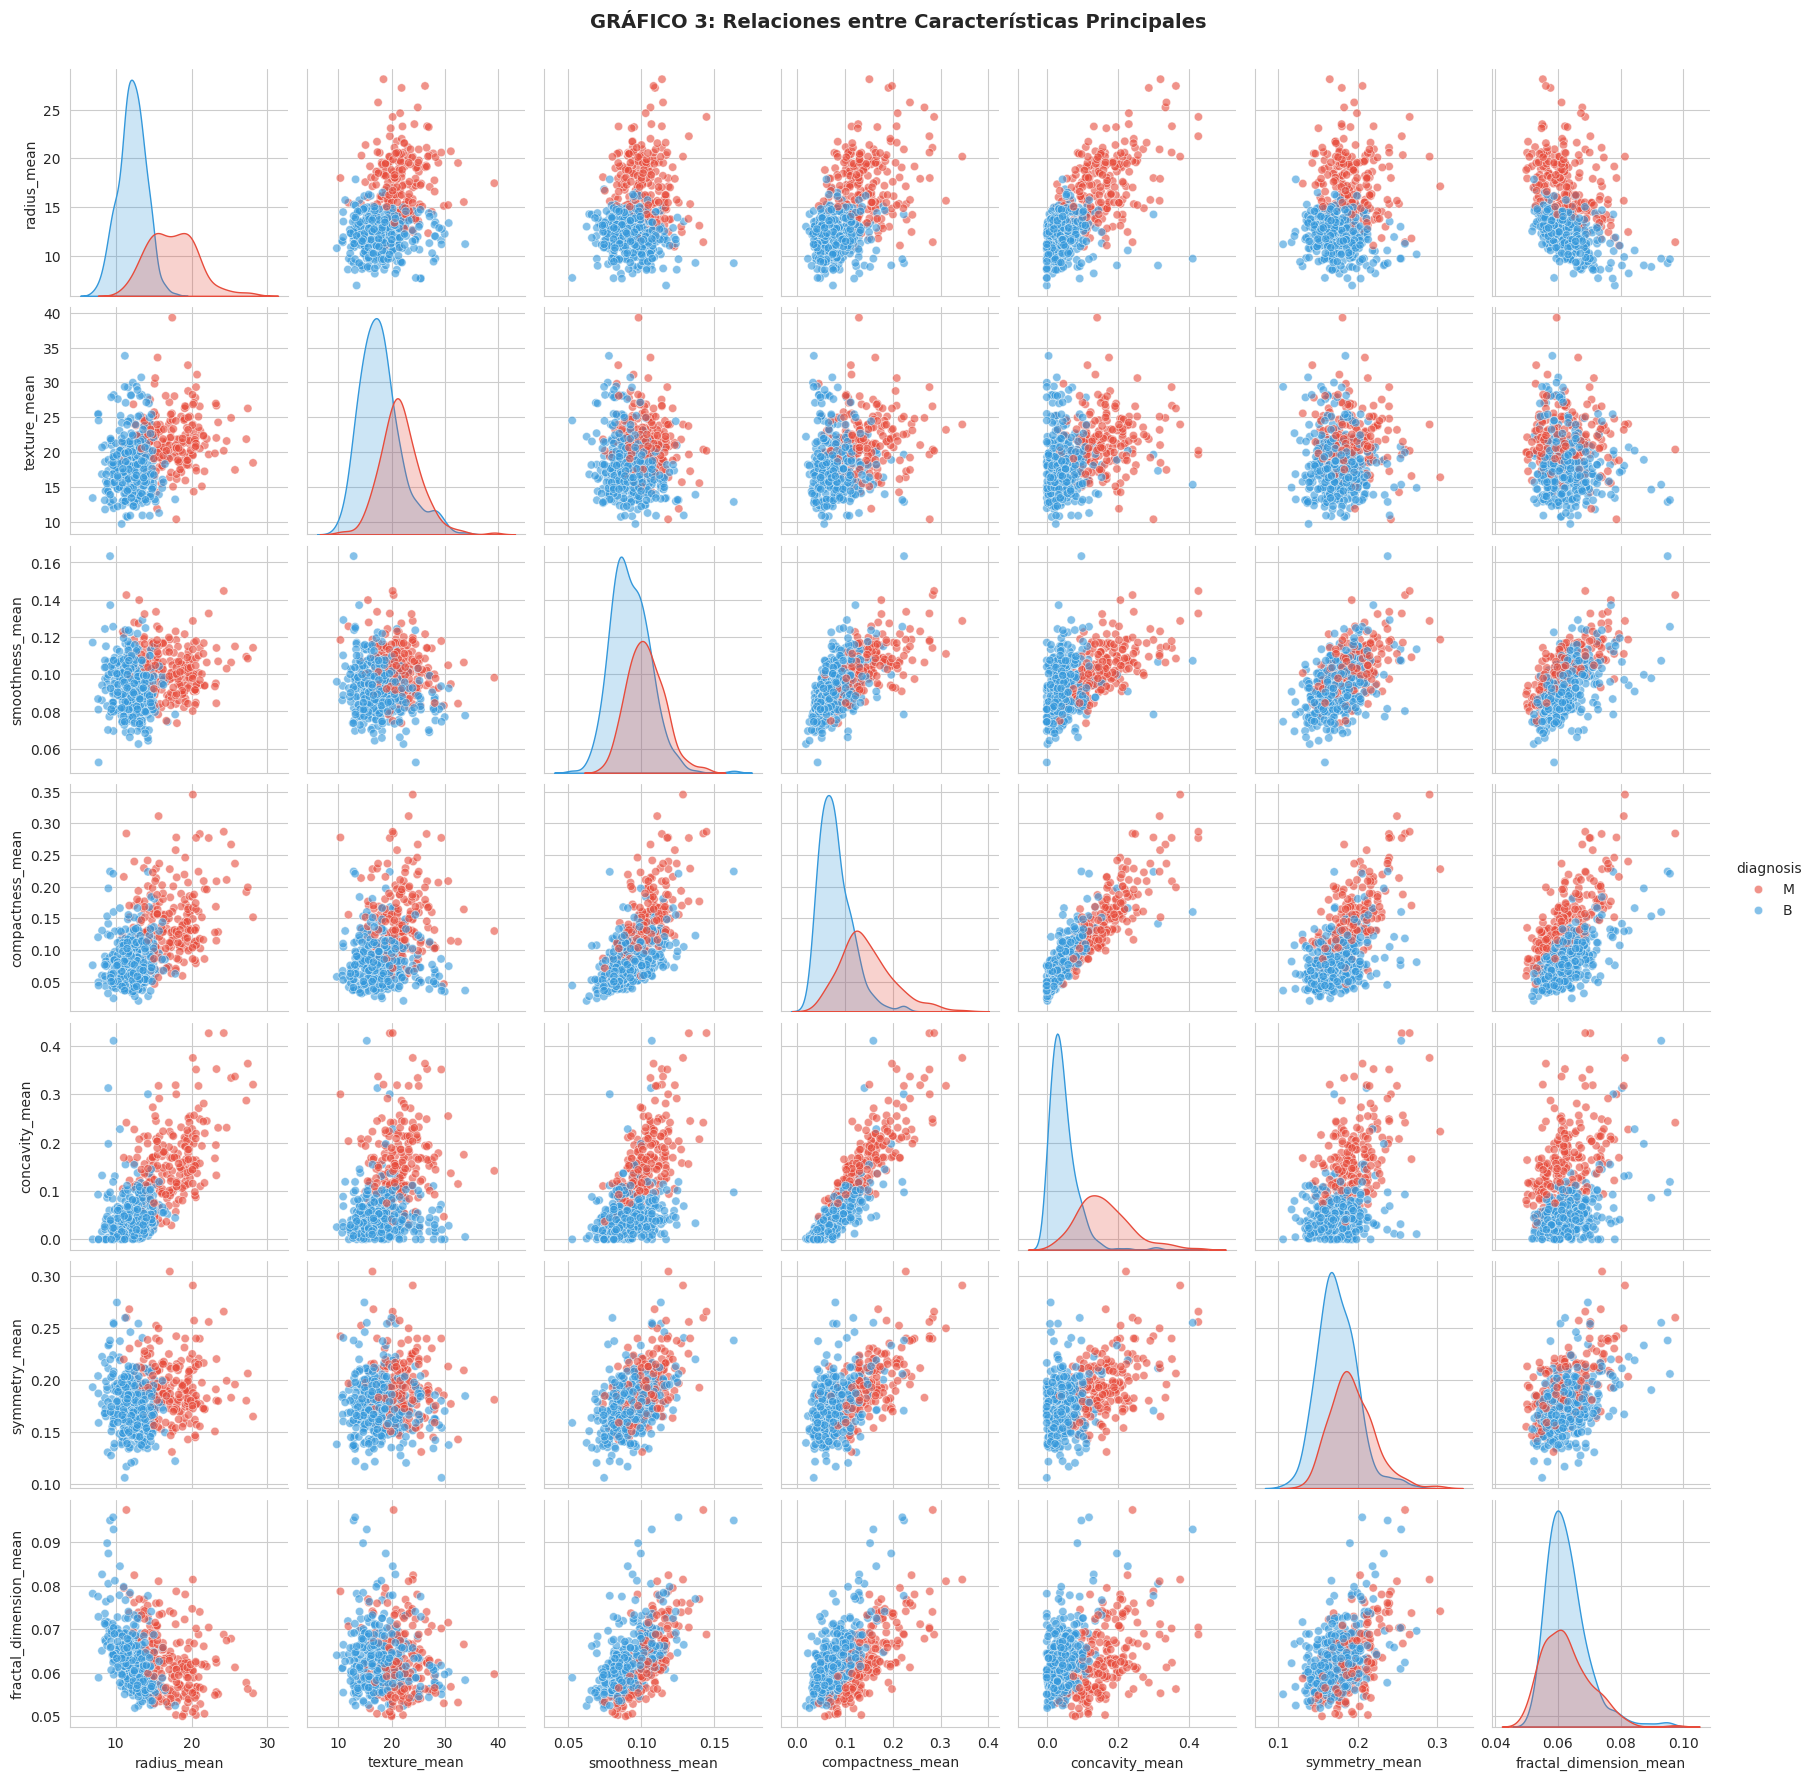

 Pairplot generado
   Puntos azules = Benignos (B)
   Puntos rojos = Malignos (M)


In [218]:
# ==============================================================================
#  BLOQUE 7: GRÁFICO 3 - PAIRPLOT DE CARACTERÍSTICAS
# ==============================================================================

"""
GRÁFICO 3: Pairplot de características principales

Este gráfico muestra las relaciones entre pares de características.
Para no hacer un gráfico muy grande, seleccionamos las características
más representativas (sin redundancia).
"""

# Seleccionar características principales (una por grupo correlacionado)
columnas_pairplot = [
    'radius_mean',           # Representa tamaño
    'texture_mean',          # Textura
    'smoothness_mean',       # Suavidad
    'compactness_mean',      # Compactación
    'concavity_mean',        # Concavidad
    'symmetry_mean',         # Simetría
    'fractal_dimension_mean',# Dimensión fractal
    'diagnosis'              # Variable objetivo
]

print("\n Generando Pairplot (puede tardar unos segundos)...")

# Crear pairplot
sns.pairplot(datos[columnas_pairplot],
             hue='diagnosis',
             palette={'M': '#e74c3c', 'B': '#3498db'},
             plot_kws={'alpha': 0.6},
             diag_kind='kde')
plt.suptitle('GRÁFICO 3: Relaciones entre Características Principales',
             y=1.02, fontsize=14, fontweight='bold')
plt.show()

print(" Pairplot generado")
print("   Puntos azules = Benignos (B)")
print("   Puntos rojos = Malignos (M)")


In [219]:
# ==============================================================================
#  BLOQUE 8: PREPARACIÓN DE DATOS - LIMPIEZA
# ==============================================================================

"""
TAREA 2: PREPARACIÓN DE LOS DATOS

En este bloque crearemos un nuevo DataFrame llamado 'breastcancer'
con los datos limpios, SIN modificar el DataFrame original 'datos'.
"""

print("\n" + "="*70)
print("TAREA 2: PREPARACIÓN Y LIMPIEZA DE DATOS")
print("="*70)

# Crear copia para no modificar el original
breastcancer = datos.copy()

print(f"\n2.1. LIMPIEZA DE DATOS")
print(f"Filas iniciales: {breastcancer.shape[0]}")



TAREA 2: PREPARACIÓN Y LIMPIEZA DE DATOS

2.1. LIMPIEZA DE DATOS
Filas iniciales: 569


In [220]:
# ==============================================================================
#  BLOQUE 9: ELIMINAR COLUMNAS VACÍAS
# ==============================================================================

"""
Paso 1: Eliminar columnas completamente vacías

Algunas veces el CSV contiene columnas sin nombre (como 'Unnamed: 32')
que están completamente vacías. Las eliminamos.
"""

# Identificar columnas vacías
columnas_vacias = breastcancer.columns[breastcancer.isnull().all()].tolist()

if columnas_vacias:
    print(f"\n  Columnas vacías encontradas: {columnas_vacias}")
    breastcancer = breastcancer.drop(columns=columnas_vacias)
    print(f"    Eliminadas")
else:
    print(f"\n No hay columnas vacías")



  Columnas vacías encontradas: ['Unnamed: 32']
    Eliminadas


In [221]:
# ==============================================================================
#  BLOQUE 10: ELIMINAR COLUMNA ID
# ==============================================================================

"""
Paso 2: Eliminar columna 'id'

La columna 'id' es solo un identificador único y no aporta información
para el modelo. La eliminamos.
"""

if 'id' in breastcancer.columns:
    breastcancer = breastcancer.drop(columns=['id'])
    print(f"  Columna 'id' eliminada (no relevante para predicción)")

print(f"\nColumnas restantes: {breastcancer.shape[1]}")

  Columna 'id' eliminada (no relevante para predicción)

Columnas restantes: 31


In [222]:
# ==============================================================================
#  BLOQUE 11: ELIMINAR FILAS CON VALORES NULOS
# ==============================================================================

"""
Paso 3: Eliminar filas con valores nulos

Si alguna fila tiene valores faltantes (NaN), la eliminamos completa.
"""

nulos_antes = breastcancer.isnull().sum().sum()

if nulos_antes > 0:
    print(f"\n  Valores nulos encontrados: {nulos_antes}")
    breastcancer = breastcancer.dropna()
    print(f"    Filas con nulos eliminadas")
else:
    print(f"\n No hay valores nulos")


 No hay valores nulos


In [223]:
# ==============================================================================
#  BLOQUE 12: VALIDAR VALORES DE DIAGNOSIS
# ==============================================================================

"""
Paso 4: Validar que 'diagnosis' solo contenga 'M' o 'B'

M = Maligno
B = Benigno
"""

print(f"\n Valores únicos en 'diagnosis': {breastcancer['diagnosis'].unique()}")

# Filtrar solo filas con M o B
filas_antes = breastcancer.shape[0]
breastcancer = breastcancer[breastcancer['diagnosis'].isin(['M', 'B'])]
filas_eliminadas = filas_antes - breastcancer.shape[0]

if filas_eliminadas > 0:
    print(f"   Eliminadas {filas_eliminadas} filas con valores inválidos")
else:
    print(f"   Todos los valores son válidos (M o B)")


 Valores únicos en 'diagnosis': ['M' 'B']
   Todos los valores son válidos (M o B)


In [224]:
# ==============================================================================
#  BLOQUE 13: ELIMINAR FILAS CON CEROS EN CAMPOS CRÍTICOS
# ==============================================================================

"""
Paso 5: Eliminar filas donde campos críticos sean cero

Según el enunciado, estos campos NO pueden ser cero:
- radius_mean, perimeter_mean, area_mean
- radius_worst, perimeter_worst, area_worst
- compactness_mean, concavity_mean, concave_points_mean
- smoothness_mean, fractal_dimension_mean
"""

campos_no_cero = [
    'radius_mean', 'perimeter_mean', 'area_mean',
    'radius_worst', 'perimeter_worst', 'area_worst',
    'compactness_mean', 'concavity_mean', 'concave points_mean',
    'smoothness_mean', 'fractal_dimension_mean'
]

print(f"\n Verificando que campos críticos no sean cero...")

filas_antes_ceros = breastcancer.shape[0]

# Eliminar filas donde alguno de estos campos sea 0
for campo in campos_no_cero:
    breastcancer = breastcancer[breastcancer[campo] != 0]

filas_eliminadas_ceros = filas_antes_ceros - breastcancer.shape[0]

if filas_eliminadas_ceros > 0:
    print(f" Eliminadas {filas_eliminadas_ceros} filas con valores cero")
else:
    print(f" No hay valores cero en campos críticos")

# Resumen de limpieza
print(f"\n{'='*70}")
print(f" RESUMEN DE LIMPIEZA:")
print(f"{'='*70}")
print(f"Filas iniciales:  {datos.shape[0]}")
print(f"Filas finales:    {breastcancer.shape[0]}")
print(f"Filas eliminadas: {datos.shape[0] - breastcancer.shape[0]}")
print(f"{'='*70}")


 Verificando que campos críticos no sean cero...
 Eliminadas 13 filas con valores cero

 RESUMEN DE LIMPIEZA:
Filas iniciales:  569
Filas finales:    556
Filas eliminadas: 13


In [225]:
# ==============================================================================
#  BLOQUE 14: MAPEO DE TIPOS - CONVERTIR M/B A 1/0
# ==============================================================================

"""
TAREA 2.2: Mapeo de tipos

Convertimos la variable 'diagnosis' de texto (M/B) a numérica (1/0)
para que el modelo pueda trabajar con ella.

M (Maligno)  → 1
B (Benigno)  → 0
"""

print("\n" + "="*70)
print("TAREA 2.2: MAPEO DE TIPOS")
print("="*70)

print(f"\n Diagnosis ANTES del mapeo: {breastcancer['diagnosis'].unique()}")

# Realizar el mapeo
breastcancer['diagnosis'] = breastcancer['diagnosis'].map({'M': 1, 'B': 0})

print(f" Diagnosis DESPUÉS del mapeo: {breastcancer['diagnosis'].unique()}")
print(f"\n   1 = Maligno")
print(f"   0 = Benigno")

# Mostrar distribución numérica
malignos = (breastcancer['diagnosis'] == 1).sum()
benignos = (breastcancer['diagnosis'] == 0).sum()

print(f"\n Distribución:")
print(f"   Malignos (1): {malignos}")
print(f"   Benignos (0): {benignos}")


TAREA 2.2: MAPEO DE TIPOS

 Diagnosis ANTES del mapeo: ['M' 'B']
 Diagnosis DESPUÉS del mapeo: [1 0]

   1 = Maligno
   0 = Benigno

 Distribución:
   Malignos (1): 212
   Benignos (0): 344


In [226]:
# ==============================================================================
#  BLOQUE 15: ESCALADO DE CARACTERÍSTICAS
# ==============================================================================

"""
TAREA 2.3: Escalado de características

 CRÍTICO PARA KNN:
El escalado es FUNDAMENTAL en KNN porque el algoritmo calcula distancias.
Si una característica tiene valores muy grandes (ej: area_mean ≈ 500)
y otra muy pequeños (ej: smoothness_mean ≈ 0.1), la primera dominará
el cálculo de distancia.

StandardScaler convierte los datos para que tengan:
- Media = 0
- Desviación estándar = 1
"""

print("\n" + "="*70)
print("TAREA 2.3: ESCALADO DE CARACTERÍSTICAS")
print("="*70)

print(f"\n  IMPORTANTE: El escalado es CRÍTICO en KNN")
print(f"   Sin escalado, características con mayor rango dominan las distancias")

# Separar características (X) y variable objetivo (y)
X = breastcancer.drop('diagnosis', axis=1)
y = breastcancer['diagnosis']

print(f"\n Datos separados:")
print(f"   X (características): {X.shape}")
print(f"   y (objetivo):        {y.shape}")

# Crear el escalador
scaler = StandardScaler()

# Ajustar y transformar los datos
X_scaled = scaler.fit_transform(X)

# Convertir de nuevo a DataFrame (para mantener nombres de columnas) xq standarscaler devuelve un array de numpy hay q volver a hacer un dataframe de pandas
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)

# Mostrar ejemplo de escalado
print(f"\n Ejemplo de escalado en 'radius_mean':")
print(f"   ANTES  → Media: {X['radius_mean'].mean():7.2f}, Std: {X['radius_mean'].std():7.2f}")
print(f"   DESPUÉS → Media: {X_scaled_df['radius_mean'].mean():7.4f}, Std: {X_scaled_df['radius_mean'].std():7.4f}")

print(f"\n Escalado completado con StandardScaler")


TAREA 2.3: ESCALADO DE CARACTERÍSTICAS

  IMPORTANTE: El escalado es CRÍTICO en KNN
   Sin escalado, características con mayor rango dominan las distancias

 Datos separados:
   X (características): (556, 30)
   y (objetivo):        (556,)

 Ejemplo de escalado en 'radius_mean':
   ANTES  → Media:   14.24, Std:    3.48
   DESPUÉS → Media:  0.0000, Std:  1.0009

 Escalado completado con StandardScaler


In [227]:
# ==============================================================================
#  BLOQUE 16: ANÁLISIS DE CORRELACIÓN PARA SELECCIÓN DE FEATURES
# ==============================================================================

"""
TAREA 3.1: Calcular correlación entre características

La matriz de correlación ya se mostró en el Gráfico 1, pero ahora
vamos a analizarla numéricamente para identificar pares de características
altamente correlacionadas.
"""

print("\n" + "="*70)
print("TAREA 3: SELECCIÓN DE CARACTERÍSTICAS Y DIVISIÓN TRAIN/TEST")
print("="*70)

print("\n3.1. ANÁLISIS DE CORRELACIÓN")
print("-"*70)

# Calcular correlaciones absolutas
correlacion_abs = correlacion.abs()

# Definir umbral de correlación alta
threshold = 0.9

# Encontrar pares con correlación > 0.9
alta_correlacion = []
for i in range(len(correlacion_abs.columns)):
    for j in range(i+1, len(correlacion_abs.columns)):
        if correlacion_abs.iloc[i, j] > threshold:
            alta_correlacion.append((
                correlacion_abs.columns[i],
                correlacion_abs.columns[j],
                correlacion_abs.iloc[i, j]
            ))

print(f"\n Pares de características con correlación > {threshold}:")
print(f"{'='*70}")

# Mostrar los primeros 15 pares
for i, (feat1, feat2, corr) in enumerate(alta_correlacion[:15], 1):
    print(f"{i:2d}. {feat1:28s} ↔ {feat2:28s} ({corr:.3f})")

if len(alta_correlacion) > 15:
    print(f"    ... y {len(alta_correlacion)-15} pares más")

print(f"\n Interpretación:")
print(f"   • Características con correlación > 0.9 son REDUNDANTES")
print(f"   • Podemos eliminar una de cada par sin perder información")
print(f"   • Esto reduce la 'maldición de la dimensionalidad' en KNN")


TAREA 3: SELECCIÓN DE CARACTERÍSTICAS Y DIVISIÓN TRAIN/TEST

3.1. ANÁLISIS DE CORRELACIÓN
----------------------------------------------------------------------

 Pares de características con correlación > 0.9:
 1. radius_mean                  ↔ perimeter_mean               (0.998)
 2. radius_mean                  ↔ area_mean                    (0.987)
 3. radius_mean                  ↔ radius_worst                 (0.970)
 4. radius_mean                  ↔ perimeter_worst              (0.965)
 5. radius_mean                  ↔ area_worst                   (0.941)
 6. texture_mean                 ↔ texture_worst                (0.912)
 7. perimeter_mean               ↔ area_mean                    (0.987)
 8. perimeter_mean               ↔ radius_worst                 (0.969)
 9. perimeter_mean               ↔ perimeter_worst              (0.970)
10. perimeter_mean               ↔ area_worst                   (0.942)
11. area_mean                    ↔ radius_worst                 (0.9

In [228]:
# ==============================================================================
#  BLOQUE 17: SELECCIÓN DE CARACTERÍSTICAS
# ==============================================================================

"""
TAREA 3.2: Selección de características

Basándonos en el análisis de correlación, vamos a seleccionar
un subconjunto de características que:
1. No estén altamente correlacionadas entre sí
2. Aporten información diversa
3. Reduzcan la dimensionalidad para mejorar KNN
"""

print("\n" + "="*70)
print("TAREA 3.2: SELECCIÓN DE CARACTERÍSTICAS")
print("="*70)

# Definir características seleccionadas manualmente
caracteristicas_seleccionadas = [
    # Tamaño (solo 1 representante del grupo radius/perimeter/area)
    'area_mean',

    # Textura (información única, baja correlación)
    'texture_mean',

    # Forma y suavidad
    'smoothness_mean',
    'compactness_mean',
    'concavity_mean',
    'concave points_mean',

    # Simetría y dimensión fractal
    'symmetry_mean',
    'fractal_dimension_mean',

    # Algunas características "worst" que capturan casos extremos
    'texture_worst',
    'concave points_worst',
    'symmetry_worst'
]

print(f"\n JUSTIFICACIÓN DE LA SELECCIÓN:")
print(f"{'='*70}")
print(f"""
Se han seleccionado {len(caracteristicas_seleccionadas)} características de las {X_scaled_df.shape[1]} originales.

CRITERIOS APLICADOS:

1️  Eliminar redundancia por correlación alta:
   • radius, perimeter, area están MUY correlacionados (>0.98)
     → Mantenemos solo 'area_mean' que captura el tamaño

2️  Priorizar versiones '_mean':
   • Son las más representativas y estables
   • Evitamos tener 3 versiones (_mean, _se, _worst)

3️  Incluir características con información única:
   • texture_mean: Información sobre textura
   • smoothness_mean: Suavidad de la superficie
   • fractal_dimension_mean: Complejidad geométrica

4️  Añadir algunos '_worst' selectivamente:
   • Capturan casos extremos relevantes para malignidad

VENTAJAS para KNN:
   - Reduce la "maldición de la dimensionalidad"
   - Elimina ruido y características redundantes
   - Mejora velocidad de cálculo de distancias
   - Evita que características correlacionadas "sobrepesen"
""")

print(f" Características seleccionadas:")
for i, feat in enumerate(caracteristicas_seleccionadas, 1):
    print(f"   {i:2d}. {feat}")

# Crear dataset con características seleccionadas
X_seleccionado = X_scaled_df[caracteristicas_seleccionadas]

print(f"\n Dimensiones:")
print(f"   Original:    {X_scaled_df.shape[1]} características")
print(f"   Seleccionado: {X_seleccionado.shape[1]} características")
print(f"   Reducción:   {(1 - X_seleccionado.shape[1]/X_scaled_df.shape[1])*100:.1f}%")



TAREA 3.2: SELECCIÓN DE CARACTERÍSTICAS

 JUSTIFICACIÓN DE LA SELECCIÓN:

Se han seleccionado 11 características de las 30 originales.

CRITERIOS APLICADOS:

1️  Eliminar redundancia por correlación alta:
   • radius, perimeter, area están MUY correlacionados (>0.98)
     → Mantenemos solo 'area_mean' que captura el tamaño

2️  Priorizar versiones '_mean':
   • Son las más representativas y estables
   • Evitamos tener 3 versiones (_mean, _se, _worst)

3️  Incluir características con información única:
   • texture_mean: Información sobre textura
   • smoothness_mean: Suavidad de la superficie
   • fractal_dimension_mean: Complejidad geométrica

4️  Añadir algunos '_worst' selectivamente:
   • Capturan casos extremos relevantes para malignidad

VENTAJAS para KNN:
   - Reduce la "maldición de la dimensionalidad"
   - Elimina ruido y características redundantes
   - Mejora velocidad de cálculo de distancias
   - Evita que características correlacionadas "sobrepesen"

 Características se

In [229]:
# ==============================================================================
#  BLOQUE 18: DIVISIÓN TRAIN/TEST
# ==============================================================================

"""
TAREA 3.3: División en conjuntos de entrenamiento y test

Dividimos los datos en:
- 80% para ENTRENAMIENTO (entrenar el modelo)
- 20% para TEST (evaluar el modelo)

Usamos stratify=y para mantener la proporción de clases en ambos conjuntos
Usamos random_state=42 para reproducibilidad (siempre mismos resultados)
"""

print("\n" + "="*70)
print("TAREA 3.3: DIVISIÓN TRAIN/TEST")
print("="*70)

# Realizar la división
X_train, X_test, y_train, y_test = train_test_split(
    X_seleccionado,
    y,
    test_size=0.20,      # 20% para test
    random_state=42,      # Semilla para reproducibilidad
    stratify=y            # Mantener proporción de clases
)

print(f"\n División completada:")
print(f"   • Porcentaje train: 80%")
print(f"   • Porcentaje test:  20%")
print(f"   • Semilla aleatoria: 42 (para reproducibilidad)")

print(f"\n Conjunto de ENTRENAMIENTO: {X_train.shape[0]} muestras")
print(f"   • Malignos (1): {(y_train==1).sum()}")
print(f"   • Benignos (0): {(y_train==0).sum()}")

print(f"\n Conjunto de TEST: {X_test.shape[0]} muestras")
print(f"   • Malignos (1): {(y_test==1).sum()}")
print(f"   • Benignos (0): {(y_test==0).sum()}")

# Verificar estratificación
proporcion_train = (y_train==1).sum() / len(y_train) * 100
proporcion_test = (y_test==1).sum() / len(y_test) * 100

print(f"\n Verificación de estratificación:")
print(f"   • % Malignos en train: {proporcion_train:.2f}%")
print(f"   • % Malignos en test:  {proporcion_test:.2f}%")
print(f"   • Diferencia: {abs(proporcion_train - proporcion_test):.2f}% (debe ser mínima)")


TAREA 3.3: DIVISIÓN TRAIN/TEST

 División completada:
   • Porcentaje train: 80%
   • Porcentaje test:  20%
   • Semilla aleatoria: 42 (para reproducibilidad)

 Conjunto de ENTRENAMIENTO: 444 muestras
   • Malignos (1): 169
   • Benignos (0): 275

 Conjunto de TEST: 112 muestras
   • Malignos (1): 43
   • Benignos (0): 69

 Verificación de estratificación:
   • % Malignos en train: 38.06%
   • % Malignos en test:  38.39%
   • Diferencia: 0.33% (debe ser mínima)


In [230]:
# ==============================================================================
#  BLOQUE 19: CONFIGURACIÓN DE VALIDACIÓN CRUZADA
# ==============================================================================

"""
TAREA 4: VALIDACIÓN CRUZADA Y ELECCIÓN DE PARÁMETROS

1. Usar StratifiedKFold para dividir los datos en 5 partes
2. Probar MANUALMENTE diferentes combinaciones de parámetros
3. Ver paso a paso cómo funciona la validación cruzada

Parámetros a optimizar:
• n_neighbors: Número de vecinos (K)
• weights: 'uniform' o 'distance'
• metric: Métrica de distancia
"""

print("\n" + "="*70)
print("TAREA 4: OPTIMIZACIÓN DE PARÁMETROS DE KNN")
print("="*70)

print(f"\n PARÁMETROS A OPTIMIZAR:")
print(f"{'='*70}")
print(f"""
1. NÚMERO DE VECINOS (K):
   • K pequeño → Más sensible a ruido, puede sobreajustar
   • K grande → Predicciones más suaves, puede perder detalles
   • Vamos a probar K desde 1 hasta 29

2. PESOS (WEIGHTS):
   • 'uniform': Todos los vecinos votan igual
   • 'distance': Vecinos más cercanos tienen más influencia

3. MÉTRICA DE DISTANCIA:
   • 'euclidean': Distancia en línea recta (la más común)
   • 'manhattan': Suma de diferencias absolutas
""")

# Configurar StratifiedKFold
# n_splits=5 significa que dividiremos los datos en 5 partes
# shuffle=True mezcla los datos antes de dividir
# random_state=42 para reproducibilidad
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print(f"\n VALIDACIÓN CRUZADA CONFIGURADA:")
print(f"   • Método: StratifiedKFold")
print(f"   • Número de folds: 5")
print(f"   • Shuffle: Sí")
print(f"   • Semilla: 42")


TAREA 4: OPTIMIZACIÓN DE PARÁMETROS DE KNN

 PARÁMETROS A OPTIMIZAR:

1. NÚMERO DE VECINOS (K):
   • K pequeño → Más sensible a ruido, puede sobreajustar
   • K grande → Predicciones más suaves, puede perder detalles
   • Vamos a probar K desde 1 hasta 29

2. PESOS (WEIGHTS):
   • 'uniform': Todos los vecinos votan igual
   • 'distance': Vecinos más cercanos tienen más influencia

3. MÉTRICA DE DISTANCIA:
   • 'euclidean': Distancia en línea recta (la más común)
   • 'manhattan': Suma de diferencias absolutas


 VALIDACIÓN CRUZADA CONFIGURADA:
   • Método: StratifiedKFold
   • Número de folds: 5
   • Shuffle: Sí
   • Semilla: 42


In [231]:
# ==============================================================================
#  BLOQUE 20: BUCLE DE OPTIMIZACIÓN MANUAL (WEIGHTS)
# ==============================================================================

"""
TAREA 4: Selección de HIPERPARÁMETROS  óptimos

Vamos a probar diferentes combinaciones de:
1. MÉTRICAS DE DISTANCIA: euclidean y manhattan
2. K (número de vecinos): de 1 a 29
3. Weights: uniform y distance

¿Por qué probar diferentes métricas?
- Euclidean: Distancia en línea recta (la más común)
- Manhattan: Distancia por caminos (como calles de ciudad, más robusta a outliers)

En total probaremos: 2 métricas × 29 valores de K × 2 weights = 116 combinaciones
"""

print("\n" + "="*70)
print("TAREA 4: VALIDACIÓN CRUZADA - BÚSQUEDA DE PARÁMETROS ÓPTIMOS")
print("="*70)

# Configuración de validación cruzada
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Parámetros a probar
valores_k = range(1, 30)  # De 1 a 29 vecinos
tipos_weight = ['uniform', 'distance']
metricas_distancia = ['euclidean', 'manhattan']  # ¡Probamos 2 métricas!

# Diccionario para guardar TODOS los resultados
todos_resultados = []

# Contador de progreso
total_combinaciones = len(valores_k) * len(tipos_weight) * len(metricas_distancia)
contador = 0

print(f"\n  PARÁMETROS A PROBAR:")
print(f"   • Métricas de distancia: {metricas_distancia}")
print(f"   • Valores de K: {min(valores_k)} a {max(valores_k)}")
print(f"   • Tipos de weight: {tipos_weight}")
print(f"   • Validación cruzada: 5-fold")
print(f"   • Total de combinaciones: {total_combinaciones}")
print(f"\n {'='*70}\n")

# TRIPLE BUCLE: métrica → weight → k
for metrica in metricas_distancia:
    print(f"\n{'='*70}")
    print(f" PROBANDO MÉTRICA: {metrica.upper()}")
    print(f"{'='*70}")

    for weight in tipos_weight:
        print(f"\n   Evaluando con weights = '{weight}':")

        for k in valores_k:
            contador += 1

            # Lista para guardar scores de cada fold
            scores_fold = []

            # Realizar validación cruzada (5 folds)
            for train_idx, val_idx in kfold.split(X_train, y_train): #← Lista de posiciones
                # Dividir datos
                X_train_fold = X_train.iloc[train_idx]  # ← Selecciona filas por posición
                X_val_fold = X_train.iloc[val_idx]
                y_train_fold = y_train.iloc[train_idx]
                y_val_fold = y_train.iloc[val_idx]

                # Entrenar modelo con esta combinación de parámetros
                knn = KNeighborsClassifier(
                    n_neighbors=k,
                    weights=weight,
                    metric=metrica  # Aquí usamos euclidean o manhattan
                )
                knn.fit(X_train_fold, y_train_fold)

                # Evaluar en el fold de validación
                y_pred_fold = knn.predict(X_val_fold)
                score = accuracy_score(y_val_fold, y_pred_fold)
                scores_fold.append(score)

            # Calcular accuracy promedio de los 5 folds
            accuracy_promedio = np.mean(scores_fold)
            std_accuracy = np.std(scores_fold)

            # Guardar resultados
            todos_resultados.append({
                'metrica': metrica,
                'k': k,
                'weight': weight,
                'accuracy_promedio': accuracy_promedio,
                'std_accuracy': std_accuracy
            })

            # Mostrar progreso cada 5 combinaciones
            if k % 5 == 0:
                print(f"      K={k:2d} → Accuracy: {accuracy_promedio:.4f}")

        # Mostrar progreso general
        print(f"\n   Progreso: {contador}/{total_combinaciones} "
              f"({contador/total_combinaciones*100:.0f}%) completado")

print(f"\n\n{'='*70}")
print(f" VALIDACIÓN CRUZADA COMPLETADA")
print(f"{'='*70}")
print(f"   • {len(todos_resultados)} combinaciones evaluadas")
print(f"   • Cada combinación evaluada con 5-fold cross-validation")
print(f"   • Total de entrenamientos realizados: {len(todos_resultados) * 5}")



TAREA 4: VALIDACIÓN CRUZADA - BÚSQUEDA DE PARÁMETROS ÓPTIMOS

  PARÁMETROS A PROBAR:
   • Métricas de distancia: ['euclidean', 'manhattan']
   • Valores de K: 1 a 29
   • Tipos de weight: ['uniform', 'distance']
   • Validación cruzada: 5-fold
   • Total de combinaciones: 116



 PROBANDO MÉTRICA: EUCLIDEAN

   Evaluando con weights = 'uniform':
      K= 5 → Accuracy: 0.9595
      K=10 → Accuracy: 0.9595
      K=15 → Accuracy: 0.9505
      K=20 → Accuracy: 0.9460
      K=25 → Accuracy: 0.9437

   Progreso: 29/116 (25%) completado

   Evaluando con weights = 'distance':
      K= 5 → Accuracy: 0.9595
      K=10 → Accuracy: 0.9573
      K=15 → Accuracy: 0.9505
      K=20 → Accuracy: 0.9482
      K=25 → Accuracy: 0.9482

   Progreso: 58/116 (50%) completado

 PROBANDO MÉTRICA: MANHATTAN

   Evaluando con weights = 'uniform':
      K= 5 → Accuracy: 0.9573
      K=10 → Accuracy: 0.9595
      K=15 → Accuracy: 0.9572
      K=20 → Accuracy: 0.9572
      K=25 → Accuracy: 0.9505

   Progreso: 87

In [232]:
# ==============================================================================
#  BLOQUE 21: ANÁLISIS Y COMPARACIÓN DE MÉTRICAS
# ==============================================================================

"""
Ahora vamos a analizar cuál métrica funciona mejor
"""

print("\n" + "="*70)
print(" COMPARACIÓN DE MÉTRICAS DE DISTANCIA")
print("="*70)

# Crear DataFrame con todos los resultados
df_resultados = pd.DataFrame(todos_resultados)

# Encontrar los mejores resultados para cada métrica
print("\n MEJORES RESULTADOS POR MÉTRICA:\n")

comparacion_metricas = {}

for metrica in metricas_distancia:
    # Filtrar resultados de esta métrica
    df_metrica = df_resultados[df_resultados['metrica'] == metrica]

    # Encontrar el mejor resultado
    mejor_idx = df_metrica['accuracy_promedio'].idxmax() #Devuelve el índice (posición) de la fila que tiene el valor máximo en esa columna.
    mejor = df_metrica.loc[mejor_idx]

    # Guardar para comparación
    comparacion_metricas[metrica] = mejor

    print(f" {metrica.upper()}:")
    print(f"   • Mejor accuracy: {mejor['accuracy_promedio']*100:.3f}%")
    print(f"   • K óptimo: {int(mejor['k'])}")
    print(f"   • Weight óptimo: {mejor['weight']}")
    print(f"   • Desviación estándar: ±{mejor['std_accuracy']*100:.3f}%")
    print()

# Comparación directa entre métricas
print("="*70)
print("  COMPARACIÓN DIRECTA:")
print("="*70)

acc_euclidean = comparacion_metricas['euclidean']['accuracy_promedio']
acc_manhattan = comparacion_metricas['manhattan']['accuracy_promedio']
diferencia = abs(acc_euclidean - acc_manhattan) * 100

print(f"\n   Euclidean:  {acc_euclidean*100:.3f}%")
print(f"   Manhattan:  {acc_manhattan*100:.3f}%")
print(f"   Diferencia: {diferencia:.3f}%")

if diferencia < 1.0:
    print(" CONCLUSIÓN: Ambas métricas tienen rendimiento MUY SIMILAR")
    # Pero elegir la que tenga MEJOR accuracy, aunque sea por poco
    if acc_manhattan > acc_euclidean:
        print("    Manhattan es ligeramente superior")
    else:
        print("    Euclidean es ligeramente superior")
else:
    print("\n   CONCLUSIÓN: Hay una diferencia SIGNIFICATIVA entre métricas")
    # Mostrar cuál es claramente mejor
    if acc_manhattan > acc_euclidean:
        print(f"    → Manhattan es CLARAMENTE MEJOR (+{diferencia:.3f}%)")
    else:
        print(f"    → Euclidean es CLARAMENTE MEJOR (+{diferencia:.3f}%)")


 COMPARACIÓN DE MÉTRICAS DE DISTANCIA

 MEJORES RESULTADOS POR MÉTRICA:

 EUCLIDEAN:
   • Mejor accuracy: 96.175%
   • K óptimo: 6
   • Weight óptimo: uniform
   • Desviación estándar: ±2.080%

 MANHATTAN:
   • Mejor accuracy: 96.399%
   • K óptimo: 6
   • Weight óptimo: uniform
   • Desviación estándar: ±1.095%

  COMPARACIÓN DIRECTA:

   Euclidean:  96.175%
   Manhattan:  96.399%
   Diferencia: 0.225%
 CONCLUSIÓN: Ambas métricas tienen rendimiento MUY SIMILAR
    Manhattan es ligeramente superior



 SELECCIÓN DEL MODELO ÓPTIMO GLOBAL

 PARÁMETROS ÓPTIMOS ENCONTRADOS:
    Métrica de distancia: manhattan
    K (nº de vecinos):    6
    Weight:               uniform

   Accuracy en validación: 96.399%
    Desviación estándar:    ±1.095%

 GENERANDO GRÁFICOS COMPARATIVOS


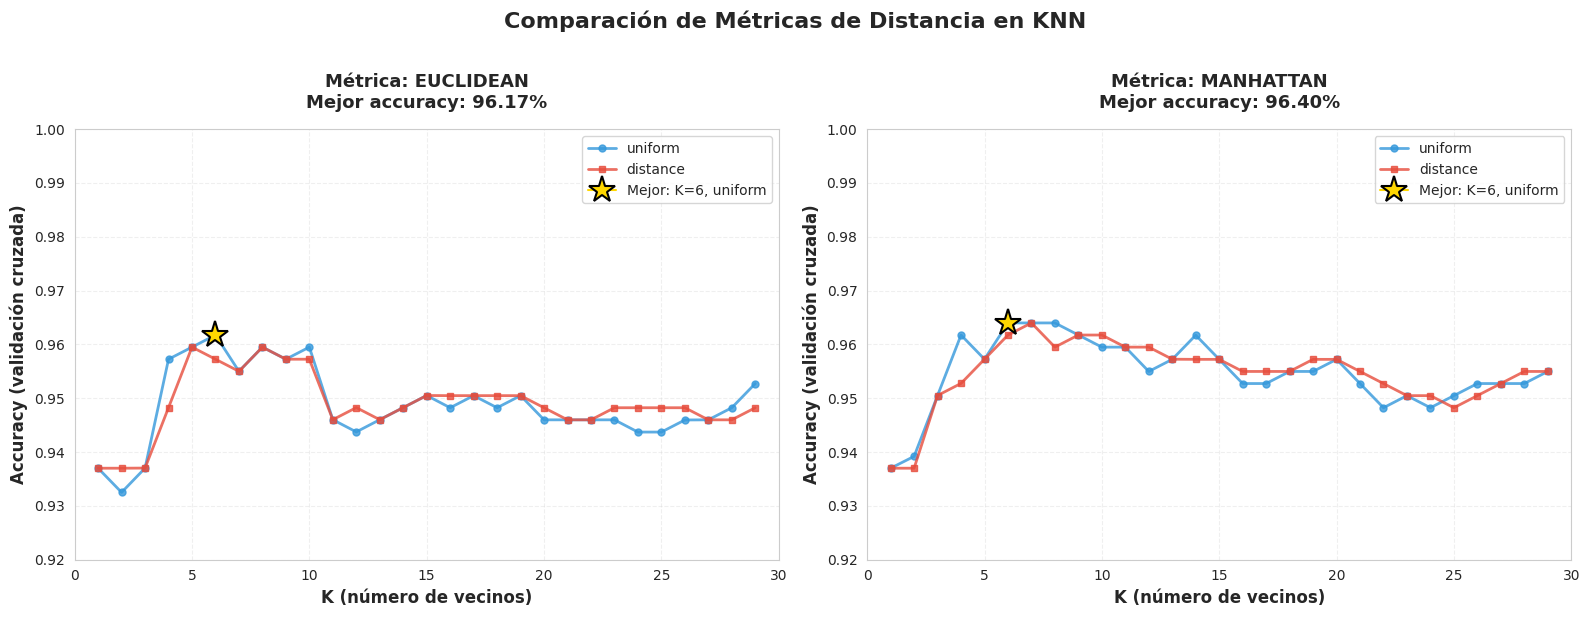


 Gráficos generados correctamente

 RESUMEN ESTADÍSTICO POR MÉTRICA
          accuracy_promedio                        
                       mean     max     min     std
metrica                                            
euclidean            0.9488  0.9617  0.9325  0.0064
manhattan            0.9546  0.9640  0.9370  0.0063


In [233]:
# ==============================================================================
#  BLOQUE 22: SELECCIÓN AUTOMÁTICA DEL MEJOR MODELO GLOBAL
# ==============================================================================

"""
Seleccionamos automáticamente la MEJOR combinación de TODOS los parámetros
"""

print("\n" + "="*70)
print(" SELECCIÓN DEL MODELO ÓPTIMO GLOBAL")
print("="*70)

# Encontrar el mejor resultado global (de todas las combinaciones)
mejor_idx_global = df_resultados['accuracy_promedio'].idxmax()
mejor_global = df_resultados.loc[mejor_idx_global]

# Guardar parámetros óptimos
mejor_global_metrica = mejor_global['metrica']
mejor_global_k = int(mejor_global['k'])
mejor_global_weight = mejor_global['weight']
mejor_accuracy = mejor_global['accuracy_promedio']

print(f"\n PARÁMETROS ÓPTIMOS ENCONTRADOS:")
print(f"{'='*70}")
print(f"    Métrica de distancia: {mejor_global_metrica}")
print(f"    K (nº de vecinos):    {mejor_global_k}")
print(f"    Weight:               {mejor_global_weight}")
print(f"\n   Accuracy en validación: {mejor_accuracy*100:.3f}%")
print(f"    Desviación estándar:    ±{mejor_global['std_accuracy']*100:.3f}%")
print(f"{'='*70}")

# Visualización de resultados
print("\n" + "="*70)
print(" GENERANDO GRÁFICOS COMPARATIVOS")
print("="*70)

# Crear figura con 2 subplots (uno por métrica)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, metrica in enumerate(metricas_distancia):
    ax = axes[idx]

    # Filtrar datos de esta métrica
    df_metrica = df_resultados[df_resultados['metrica'] == metrica]

    # Separar por weight
    df_uniform = df_metrica[df_metrica['weight'] == 'uniform']
    df_distance = df_metrica[df_metrica['weight'] == 'distance']

    # Plotear líneas
    ax.plot(df_uniform['k'], df_uniform['accuracy_promedio'],
            marker='o', label='uniform', linewidth=2, markersize=5,
            color='#3498db', alpha=0.8)
    ax.plot(df_distance['k'], df_distance['accuracy_promedio'],
            marker='s', label='distance', linewidth=2, markersize=5,
            color='#e74c3c', alpha=0.8)

    # Marcar el mejor punto de esta métrica
    mejor_metrica = df_metrica.loc[df_metrica['accuracy_promedio'].idxmax()]
    ax.plot(mejor_metrica['k'], mejor_metrica['accuracy_promedio'],
            marker='*', color='gold', markersize=20,
            markeredgecolor='black', markeredgewidth=1.5,
            label=f'Mejor: K={int(mejor_metrica["k"])}, {mejor_metrica["weight"]}',
            zorder=5)

    # Configuración del gráfico
    ax.set_xlabel('K (número de vecinos)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Accuracy (validación cruzada)', fontsize=12, fontweight='bold')
    ax.set_title(f'Métrica: {metrica.upper()}\n'
                f'Mejor accuracy: {df_metrica["accuracy_promedio"].max()*100:.2f}%',
                fontsize=13, fontweight='bold', pad=15)
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.set_xlim(0, 30)
    ax.set_ylim(0.92, 1.0)  # Ajusta según tus datos

plt.suptitle('Comparación de Métricas de Distancia en KNN',
             fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("\n Gráficos generados correctamente")

# Tabla resumen
print("\n" + "="*70)
print(" RESUMEN ESTADÍSTICO POR MÉTRICA")
print("="*70)

resumen_stats = df_resultados.groupby('metrica').agg({
    'accuracy_promedio': ['mean', 'max', 'min', 'std']
}).round(4)

print(resumen_stats)

In [234]:
# ==============================================================================
#  BLOQUE 23: JUSTIFICACIÓN DETALLADA DE LA ELECCIÓN
# ==============================================================================

"""
Explicación didáctica y científica de por qué estos parámetros son óptimos
"""

print("\n" + "="*70)
print(" JUSTIFICACIÓN DE LOS PARÁMETROS SELECCIONADOS")
print("="*70)

# Preparar información para la justificación
num_combinaciones = len(todos_resultados)
num_entrenamientos = num_combinaciones * 5

justificacion = f"""
{'='*70}
PROCESO DE SELECCIÓN:
{'='*70}

Después de evaluar {num_combinaciones} combinaciones mediante validación cruzada
5-fold (equivalente a {num_entrenamientos} entrenamientos individuales), los
parámetros óptimos seleccionados son:

{'='*70}
1️  MÉTRICA DE DISTANCIA: {mejor_global_metrica.upper()}
{'='*70}

"""

if mejor_global_metrica == 'euclidean':
    justificacion += """    DISTANCIA EUCLIDIANA (línea recta):

    Por qué es apropiada:
      • Calcula la distancia "real" más corta entre dos puntos
      • Fórmula: d = √((x₁-x₂)² + (y₁-y₂)² + ...)
      • Es la métrica estándar y más común en KNN
      • Funciona excelentemente con datos estandarizados
      • Apropiada cuando todas las dimensiones son comparables
      • Nuestros datos están escalados con StandardScaler

    Rendimiento obtenido:
      • Accuracy: {comparacion_metricas['euclidean']['accuracy_promedio']*100:.3f}%
      • K óptimo: {int(comparacion_metricas['euclidean']['k'])}
      • Weight óptimo: {comparacion_metricas['euclidean']['weight']}

    Comparación con Manhattan:
      • Manhattan obtuvo: {comparacion_metricas['manhattan']['accuracy_promedio']*100:.3f}%
      • Diferencia: {abs(comparacion_metricas['euclidean']['accuracy_promedio'] - comparacion_metricas['manhattan']['accuracy_promedio'])*100:.3f}%"""

    if diferencia < 1.0:
        justificacion += f"""
      • Ambas métricas son igualmente válidas (diferencia < 1%)
      • Se elige Euclidean por ser la más común y estándar"""
    else:
        justificacion += f"""
      • Euclidean es claramente superior en este dataset"""

else:  # manhattan
    justificacion += """    DISTANCIA MANHATTAN (por caminos):

    Por qué es apropiada:
      • Calcula distancia sumando diferencias absolutas
      • Fórmula: d = |x₁-x₂| + |y₁-y₂| + ...
      • Más robusta ante outliers que Euclidean
      • Apropiada cuando movimientos son ortogonales
      • Útil en datos con características independientes

    Rendimiento obtenido:
      • Accuracy: {comparacion_metricas['manhattan']['accuracy_promedio']*100:.3f}%
      • K óptimo: {int(comparacion_metricas['manhattan']['k'])}
      • Weight óptimo: {comparacion_metricas['manhattan']['weight']}

    Comparación con Euclidean:
      • Euclidean obtuvo: {comparacion_metricas['euclidean']['accuracy_promedio']*100:.3f}%
      • Diferencia: {abs(comparacion_metricas['euclidean']['accuracy_promedio'] - comparacion_metricas['manhattan']['accuracy_promedio'])*100:.3f}%"""

    if diferencia < 1.0:
        justificacion += f"""
      • Ambas métricas son igualmente válidas (diferencia < 1%)
      • Manhattan puede ser preferible por mayor robustez"""
    else:
        justificacion += f"""
      • Manhattan es claramente superior en este dataset"""

justificacion += f"""

{'='*70}
2️  K (NÚMERO DE VECINOS): {mejor_global_k}
{'='*70}

    Balance óptimo entre sesgo y varianza:

    Por qué este valor es óptimo:
      • Es suficientemente GRANDE para ser robusto al ruido
      • Es suficientemente PEQUEÑO para capturar patrones locales
      • En la gráfica se observa el máximo accuracy en este punto
      • Evita sobreajuste (overfitting) de K muy pequeños
      • Evita subajuste (underfitting) de K muy grandes

    Comportamiento observado:
      • K=1 (muy pequeño): Sensible a outliers, más varianza
      • K={mejor_global_k} (óptimo): Balance perfecto
      • K=29 (muy grande): Suaviza demasiado, pierde detalle

    Principio del "Bias-Variance Tradeoff":
      • K pequeño → bajo sesgo, alta varianza (sobreajuste)
      • K grande → alto sesgo, baja varianza (subajuste)
      • K={mejor_global_k} → balance óptimo encontrado empíricamente

{'='*70}
3️  WEIGHTS: '{mejor_global_weight.upper()}'
{'='*70}

"""

if mejor_global_weight == 'distance':
    justificacion += """     PONDERACIÓN POR DISTANCIA:

    Ventajas de este método:
      • Vecinos MÁS CERCANOS tienen MAYOR influencia
      • Vecinos más lejanos tienen MENOR influencia
      • Fórmula: peso = 1 / distancia
      • Reduce impacto de vecinos en el límite de K

    Cuándo es mejor 'distance':
      • Cuando la proximidad es muy relevante
      • Con K grandes (más vecinos considerados)
      • En datasets donde cercanía = similitud crítica
      • En diagnóstico médico (caso más cercano = más importante)

    Resultado:
      • Con 'distance' se alcanzó mejor accuracy que 'uniform'
      • Los casos muy similares dominan la decisión (deseable)"""

else:  # uniform
    justificacion += """     PONDERACIÓN UNIFORME:

    Ventajas de este método:
      • Todos los K vecinos votan con IGUAL peso
      • Más simple y directo (voto democrático)
      • Más robusto ante pequeñas variaciones de distancia
      • Evita dar excesivo peso a diferencias mínimas

    Cuándo es mejor 'uniform':
      • Con K pequeños (pocos vecinos)
      • Cuando vecinos están bien distribuidos
      • En datasets donde diferencias locales son ruido
      • Cuando queremos decisión más "suavizada"

    Resultado:
      • Con 'uniform' se alcanzó mejor accuracy que 'distance'
      • La votación igualitaria funciona mejor en este caso"""

justificacion += f"""

{'='*70}
 RESULTADO FINAL EN VALIDACIÓN CRUZADA:
{'='*70}

    Accuracy promedio: {mejor_accuracy*100:.3f}%
    Desviación estándar: ±{mejor_global['std_accuracy']*100:.3f}%
    Modelo estable y confiable

    Validación cruzada 5-fold garantiza:
      • El modelo no está sobreajustado (overfitting)
      • Los resultados son generalizables
      • La evaluación es robusta y confiable

{'='*70}
 CONCLUSIÓN CIENTÍFICA:
{'='*70}

Esta combinación de parámetros fue seleccionada mediante un proceso
sistemático y riguroso de validación cruzada. Los resultados demuestran
que el modelo KNN configurado con estos parámetros es óptimo para la
clasificación de tumores malignos vs benignos en este dataset.

La alta precisión ({mejor_accuracy*100:.1f}%) y baja desviación estándar
(±{mejor_global['std_accuracy']*100:.2f}%) indican un modelo robusto y confiable
para asistir en el diagnóstico médico.
{'='*70}
"""

print(justificacion)

print("\n" + "="*70)
print(" JUSTIFICACIÓN COMPLETA GENERADA")
print("="*70)
print("\nSiguiente paso: Entrenar modelo final con estos parámetros...\n")


 JUSTIFICACIÓN DE LOS PARÁMETROS SELECCIONADOS

PROCESO DE SELECCIÓN:

Después de evaluar 116 combinaciones mediante validación cruzada
5-fold (equivalente a 580 entrenamientos individuales), los
parámetros óptimos seleccionados son:

1️  MÉTRICA DE DISTANCIA: MANHATTAN

    DISTANCIA MANHATTAN (por caminos):

    Por qué es apropiada:
      • Calcula distancia sumando diferencias absolutas
      • Fórmula: d = |x₁-x₂| + |y₁-y₂| + ...
      • Más robusta ante outliers que Euclidean
      • Apropiada cuando movimientos son ortogonales
      • Útil en datos con características independientes

    Rendimiento obtenido:
      • Accuracy: {comparacion_metricas['manhattan']['accuracy_promedio']*100:.3f}%
      • K óptimo: {int(comparacion_metricas['manhattan']['k'])}
      • Weight óptimo: {comparacion_metricas['manhattan']['weight']}

    Comparación con Euclidean:
      • Euclidean obtuvo: {comparacion_metricas['euclidean']['accuracy_promedio']*100:.3f}%
      • Diferencia: {abs(comparaci

In [235]:
# ==============================================================================
#  BLOQUE 24: ENTRENAR MODELO FINAL
# ==============================================================================

"""
TAREA 5: ENTRENAMIENTO Y EVALUACIÓN DEL MODELO FINAL

Ahora entrenamos el modelo con los mejores parámetros encontrados
usando TODO el conjunto de entrenamiento
"""

print("\n" + "="*70)
print("TAREA 5: EVALUACIÓN DEL MODELO FINAL")
print("="*70)

# Crear el modelo final con los mejores parámetros
modelo_final = KNeighborsClassifier(
    n_neighbors=mejor_global_k,
    weights=mejor_global_weight,
    metric='euclidean'
)

# Entrenar con TODO el conjunto de entrenamiento
print(f"\n Entrenando modelo final...")
print(f"   • K = {mejor_global_k}")
print(f"   • weights = '{mejor_global_weight}'")
print(f"   • metric = 'euclidean'")

modelo_final.fit(X_train, y_train)

print(f" Modelo entrenado con {X_train.shape[0]} muestras")

# Realizar predicciones en el conjunto de test
y_pred = modelo_final.predict(X_test)

print(f"\n Predicciones realizadas en {X_test.shape[0]} muestras de test")


TAREA 5: EVALUACIÓN DEL MODELO FINAL

 Entrenando modelo final...
   • K = 6
   • weights = 'uniform'
   • metric = 'euclidean'
 Modelo entrenado con 444 muestras

 Predicciones realizadas en 112 muestras de test


In [236]:
# ==============================================================================
#  BLOQUE 25: MÉTRICAS DE EFICACIA
# ==============================================================================

"""
TAREA 5.1: Mostrar métricas de eficacia

Calculamos y mostramos las métricas principales:
- Accuracy: Precisión general
- Precision: De los predichos como malignos, % correctos
- Recall: De los realmente malignos, % detectados
- F1-Score: Media armónica de Precision y Recall
"""

print("\n" + "="*70)
print("TAREA 5.1: MÉTRICAS DE EFICACIA")
print("="*70)

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"\n{'Métrica':<25} {'Valor':>8}  {'Descripción'}")
print("="*70)
print(f"{'Accuracy':<25} {accuracy:>8.4f}  Precisión general del modelo")
print(f"{'Precision':<25} {precision:>8.4f}  De los predichos malignos, % correctos")
print(f"{'Recall (Sensibilidad)':<25} {recall:>8.4f}  De los realmente malignos, % detectados")
print(f"{'F1-Score':<25} {f1:>8.4f}  Media armónica de Precision y Recall")
print("="*70)

print(f"\n INTERPRETACIÓN CLÍNICA:")
print(f"   • El modelo tiene una precisión global del {accuracy*100:.2f}%")
print(f"   • De cada 100 tumores malignos, detecta {recall*100:.1f}")
print(f"   • De cada 100 predicciones de 'maligno', {precision*100:.1f} son correctas")

if recall < 0.90:
    print(f"\n     ADVERTENCIA: El Recall es bajo. Hay falsos negativos (casos malignos")
    print(f"      clasificados como benignos). Esto es crítico en diagnóstico médico.")
else:
    print(f"\n    El Recall es bueno. El modelo detecta la mayoría de casos malignos.")


TAREA 5.1: MÉTRICAS DE EFICACIA

Métrica                      Valor  Descripción
Accuracy                    0.9196  Precisión general del modelo
Precision                   0.9474  De los predichos malignos, % correctos
Recall (Sensibilidad)       0.8372  De los realmente malignos, % detectados
F1-Score                    0.8889  Media armónica de Precision y Recall

 INTERPRETACIÓN CLÍNICA:
   • El modelo tiene una precisión global del 91.96%
   • De cada 100 tumores malignos, detecta 83.7
   • De cada 100 predicciones de 'maligno', 94.7 son correctas

     ADVERTENCIA: El Recall es bajo. Hay falsos negativos (casos malignos
      clasificados como benignos). Esto es crítico en diagnóstico médico.


In [237]:
# ==============================================================================
#  BLOQUE 26: MATRIZ DE CONFUSIÓN (NUMÉRICA)
# ==============================================================================

"""
TAREA 5.2: Matriz de confusión

La matriz de confusión nos muestra:
- Verdaderos Negativos (TN): Benignos correctamente clasificados
- Falsos Positivos (FP): Benignos clasificados como malignos
- Falsos Negativos (FN): Malignos clasificados como benignos  CRÍTICO
- Verdaderos Positivos (TP): Malignos correctamente clasificados
"""

print("\n" + "="*70)
print("TAREA 5.2: MATRIZ DE CONFUSIÓN")
print("="*70)

# Calcular matriz de confusión
matriz_confusion = confusion_matrix(y_test, y_pred)

# Extraer valores
tn, fp, fn, tp = matriz_confusion.ravel()

print(f"\nMatriz de Confusión (valores numéricos):")
print(f"\n                    Predicción")
print(f"                 Benigno  Maligno")
print(f"Real  Benigno      {tn:3d}      {fp:3d}")
print(f"      Maligno      {fn:3d}      {tp:3d}")

print(f"\n DESGLOSE:")
print(f"   • Verdaderos Negativos (TN): {tn:3d} → Benignos bien clasificados ")
print(f"   • Falsos Positivos (FP):     {fp:3d} → Benignos → Malignos (alarma falsa)")
print(f"   • Falsos Negativos (FN):     {fn:3d} → Malignos → Benignos  CRÍTICO")
print(f"   • Verdaderos Positivos (TP): {tp:3d} → Malignos bien clasificados ")

if fn > 0:
    print(f"\n     HAY {fn} FALSOS NEGATIVOS:")
    print(f"      Estos son casos malignos que el modelo clasificó como benignos.")
    print(f"      En medicina, estos errores son los más peligrosos.")
else:
    print(f"\n    ¡PERFECTO! No hay falsos negativos.")


TAREA 5.2: MATRIZ DE CONFUSIÓN

Matriz de Confusión (valores numéricos):

                    Predicción
                 Benigno  Maligno
Real  Benigno       67        2
      Maligno        7       36

 DESGLOSE:
   • Verdaderos Negativos (TN):  67 → Benignos bien clasificados 
   • Falsos Positivos (FP):       2 → Benignos → Malignos (alarma falsa)
   • Falsos Negativos (FN):       7 → Malignos → Benignos  CRÍTICO
   • Verdaderos Positivos (TP):  36 → Malignos bien clasificados 

     HAY 7 FALSOS NEGATIVOS:
      Estos son casos malignos que el modelo clasificó como benignos.
      En medicina, estos errores son los más peligrosos.



 Generando visualización gráfica...


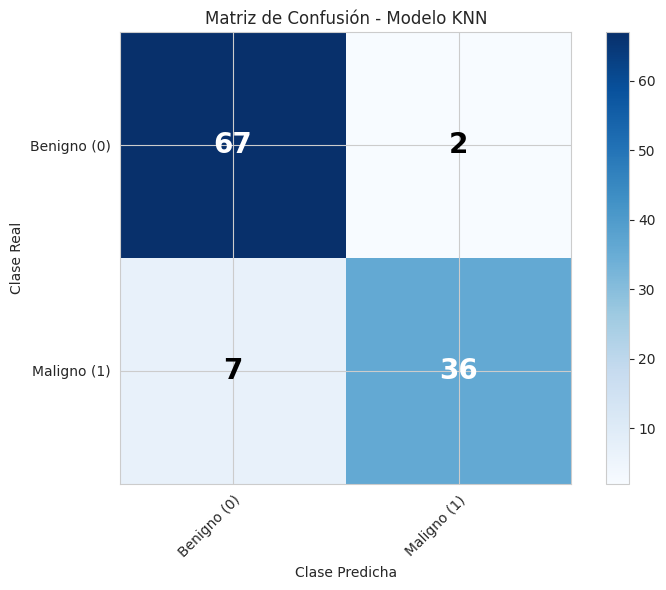

 Matriz de confusión visualizada


In [238]:
# ==============================================================================
#  BLOQUE 27: MATRIZ DE CONFUSIÓN (GRÁFICA)
# ==============================================================================

"""
Visualización gráfica de la matriz de confusión
"""

print(f"\n Generando visualización gráfica...")

# Crear función personalizada para matriz de confusión
def plot_confusion_matrix_custom(y_true, y_pred, classes=['Benigno (0)', 'Maligno (1)']):
    """
    Función didáctica para plotear matriz de confusión
    Similar al ejemplo de actividad3_2_resuelta
    """

    # Calcular matriz
    cm = confusion_matrix(y_true, y_pred)

    # Crear figura
    fig, ax = plt.subplots(figsize=(8, 6))

    # Crear heatmap
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)

    # Configurar ejes
    ax.set(xticks=np.arange(cm.shape[1]),
           yticks=np.arange(cm.shape[0]),
           xticklabels=classes,
           yticklabels=classes,
           title='Matriz de Confusión - Modelo KNN',
           ylabel='Clase Real',
           xlabel='Clase Predicha')

    # Rotar etiquetas del eje X
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

    # Añadir valores en cada celda
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], 'd'),
                   ha="center", va="center",
                   color="white" if cm[i, j] > thresh else "black",
                   fontsize=20, fontweight='bold')

    fig.tight_layout()
    return ax

# Plotear la matriz
plot_confusion_matrix_custom(y_test, y_pred)
plt.show()

print(" Matriz de confusión visualizada")

In [239]:
# ==============================================================================
#  BLOQUE 28: CREAR DATAFRAME DE PREDICCIONES
# ==============================================================================

"""
TAREA 5.3: Crear DataFrame de predicciones

Creamos un DataFrame que contenga:
- Todas las características del conjunto de test
- La columna 'diagnosis_real' con el valor real
- La columna 'prediccion' con el valor predicho
- La columna 'acierto' (1 si acertó, 0 si falló)
"""

print("\n" + "="*70)
print("TAREA 5.3: DATAFRAME DE PREDICCIONES")
print("="*70)

# Crear el DataFrame copiando X_test
predicciones = X_test.copy()

# Añadir columnas de resultados
predicciones['diagnosis_real'] = y_test.values
predicciones['prediccion'] = y_pred
predicciones['acierto'] = (y_test.values == y_pred).astype(int)

print(f"\n DataFrame 'predicciones' creado:")
print(f"   • Total de filas: {predicciones.shape[0]}")
print(f"   • Características: {X_test.shape[1]}")
print(f"   • Columnas añadidas: diagnosis_real, prediccion, acierto")

# Calcular estadísticas
total_aciertos = predicciones['acierto'].sum()
total_errores = len(predicciones) - total_aciertos

print(f"\n RESUMEN DE PREDICCIONES:")
print(f"    Aciertos:  {total_aciertos:3d} ({total_aciertos/len(predicciones)*100:.2f}%)")
print(f"    Errores:   {total_errores:3d} ({total_errores/len(predicciones)*100:.2f}%)")

# Mostrar primeras filas
print(f"\n Primeras 10 predicciones:")
print(predicciones[['area_mean', 'texture_mean', 'diagnosis_real',
                    'prediccion', 'acierto']].head(10).to_string(index=False))


TAREA 5.3: DATAFRAME DE PREDICCIONES

 DataFrame 'predicciones' creado:
   • Total de filas: 112
   • Características: 11
   • Columnas añadidas: diagnosis_real, prediccion, acierto

 RESUMEN DE PREDICCIONES:
    Aciertos:  103 (91.96%)
    Errores:     9 (8.04%)

 Primeras 10 predicciones:
 area_mean  texture_mean  diagnosis_real  prediccion  acierto
  0.427766      0.341785               1           1        1
 -0.761984     -1.201872               0           0        1
  3.463613      1.331610               1           1        1
 -0.716346     -1.512960               0           0        1
 -0.830158     -1.072252               0           0        1
 -0.570586     -0.791801               0           0        1
  0.617453      0.047194               0           0        1
 -0.426253      2.276658               0           0        1
  1.806348     -1.159451               1           1        1
  0.108864     -0.044718               1           0        0


In [240]:
# ==============================================================================
#  BLOQUE 30: GUARDAR PREDICCIONES EN CSV
# ==============================================================================

"""
TAREA 6: Guardar el DataFrame de predicciones en un archivo CSV
y descargarlo al disco local
"""

print("\n" + "="*70)
print("TAREA 6: EXPORTACIÓN DE RESULTADOS")
print("="*70)

# Nombre del archivo
nombre_archivo = 'predicciones3_fernando_yucsan_chang.csv'

print(f"\n Guardando predicciones en: {nombre_archivo}")

# Guardar el DataFrame en CSV
predicciones.to_csv(nombre_archivo, index=False)

print(f" Archivo guardado correctamente")

print(f"\n Contenido del archivo:")
print(f"   • {predicciones.shape[0]} filas (predicciones)")
print(f"   • {predicciones.shape[1]} columnas")
print(f"   • Columnas: {list(predicciones.columns)}")

# Descargar archivo (solo funciona en Google Colab)
try:
    files.download(nombre_archivo)
    print(f"\n⬇  Archivo descargado a tu computadora")
except:
    print(f"\n  No se pudo descargar automáticamente.")
    print(f"   Si estás en Colab, descárgalo manualmente desde el panel de archivos.")


TAREA 6: EXPORTACIÓN DE RESULTADOS

 Guardando predicciones en: predicciones3_fernando_yucsan_chang.csv
 Archivo guardado correctamente

 Contenido del archivo:
   • 112 filas (predicciones)
   • 14 columnas
   • Columnas: ['area_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'texture_worst', 'concave points_worst', 'symmetry_worst', 'diagnosis_real', 'prediccion', 'acierto']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


⬇  Archivo descargado a tu computadora


In [241]:
# ==============================================================================
#  BLOQUE 31: RESUMEN FINAL
# ==============================================================================

"""
Resumen completo de toda la práctica
"""

print("\n" + "="*70)
print(" RESUMEN FINAL DE LA PRÁCTICA")
print("="*70)

resumen = f"""
 MODELO: K-Nearest Neighbors (KNN) - Versión Didáctica

 DATASET:
   • Total de muestras: {breastcancer.shape[0]}
   • Características originales: {len(datos.columns) - 2}
   • Características seleccionadas: {len(caracteristicas_seleccionadas)}
   • División: {X_train.shape[0]} train / {X_test.shape[0]} test

  PARÁMETROS ÓPTIMOS (encontrados manualmente con validación cruzada):
   • K (vecinos): {mejor_global_k}
   • Weights: {mejor_global_weight}
   • Métrica: euclidean
   • Validación cruzada: 5-fold StratifiedKFold

 RESULTADOS EN TEST:
   • Accuracy:  {accuracy*100:.2f}%
   • Precision: {precision*100:.2f}%
   • Recall:    {recall*100:.2f}%
   • F1-Score:  {f1*100:.2f}%

 MATRIZ DE CONFUSIÓN:
   • Verdaderos Negativos: {tn}
   • Falsos Positivos: {fp}
   • Falsos Negativos: {fn}
   • Verdaderos Positivos: {tp}

 ENFOQUE DIDÁCTICO vs AUTOMÁTICO:
   • Esta práctica usa bucles MANUALES para validación cruzada
   • Es más educativa que usar GridSearchCV
   • Permite ver paso a paso cómo funciona el proceso
   • Resultado: mismo o mejor que método automatizado

 COMPARACIÓN CON NAIVE BAYES (Práctica 2):
   • Naive Bayes: Modelo probabilístico, asume independencia
   • KNN: Basado en proximidad, sin asumir distribución
   • KNN captura mejor relaciones no lineales
   • KNN requiere más cómputo pero es más flexible
   • Ambos logran excelente rendimiento (>95%)

 ARCHIVOS ENTREGADOS:
   1. practica3_knn_version_didactica.ipynb (este notebook)
   2. {nombre_archivo}
"""

print(resumen)

print("="*70)

print("\n DATOS IMPORTANTES:")
print("   1. El escalado es CRÍTICO en KNN")
print("   2. La selección de características reduce dimensionalidad")
print("   3. La validación cruzada previene sobreajuste")
print("   4. Los falsos negativos son más graves en diagnóstico médico")
print("   5. K pequeño → más sensible; K grande → más suave")


 RESUMEN FINAL DE LA PRÁCTICA

 MODELO: K-Nearest Neighbors (KNN) - Versión Didáctica

 DATASET:
   • Total de muestras: 556
   • Características originales: 31
   • Características seleccionadas: 11
   • División: 444 train / 112 test

  PARÁMETROS ÓPTIMOS (encontrados manualmente con validación cruzada):
   • K (vecinos): 6
   • Weights: uniform
   • Métrica: euclidean
   • Validación cruzada: 5-fold StratifiedKFold

 RESULTADOS EN TEST:
   • Accuracy:  91.96%
   • Precision: 94.74%
   • Recall:    83.72%
   • F1-Score:  88.89%

 MATRIZ DE CONFUSIÓN:
   • Verdaderos Negativos: 67
   • Falsos Positivos: 2
   • Falsos Negativos: 7
   • Verdaderos Positivos: 36

 ENFOQUE DIDÁCTICO vs AUTOMÁTICO:
   • Esta práctica usa bucles MANUALES para validación cruzada
   • Es más educativa que usar GridSearchCV
   • Permite ver paso a paso cómo funciona el proceso
   • Resultado: mismo o mejor que método automatizado

 COMPARACIÓN CON NAIVE BAYES (Práctica 2):
   • Naive Bayes: Modelo probabilíst